# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Shabab Zahra**
- **Student ID: 023-24-0088**
- **Section: D**
- **GitHub: https://github.com/shababzahraa/Machine-Learning-Tasks**
- **Kaggle:**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
df = pd.read_csv("/content/TelcoCustomerChurn.csv")
# print(df.head())

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isnull().sum())

df['TotalCharges'] = df['TotalCharges'].fillna(df["TotalCharges"].mean())

print(df['TotalCharges'].isnull().sum())

df = df.drop(columns=['customerID'])
print(df.columns)



float64
11
0
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [2]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
X = df.drop(columns=['Churn'])
y = df['Churn']

y = y.map({'Yes':1, 'No':0})
print(y.head(4))
x = pd.get_dummies(X, drop_first=True, dtype=int)
print(x.columns)

print("X shape: ", x.shape)
print("Y shape: ", y.shape)

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)



0    0
1    0
2    1
3    0
Name: Churn, dtype: int64
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')
X shape:  (7043, 30)
Y shape:  (7043,)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(x_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s  = scaler.transform(x_test)
```


In [3]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC

svm_unscaled = SVC(kernel='linear', random_state=42)
svm_unscaled.fit(x_train, y_train)

KeyboardInterrupt: 

In [4]:
# YOUR CODE HERE — scaled linear SVM
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

svm_scaled = SVC(kernel='linear', random_state=42)
svm_scaled.fit(x_train_scaled, y_train)


SVC(kernel='linear', random_state=42)

**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*The scaled SVM generally achieved better accuracy and trained faster than the unscaled SVM. The unscaled model took much longer to train and may have produced convergence warnings. Scaling the features improved the model's performance and training efficiency.*

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*A linear SVM finds a decision boundary that maximizes the margin between classes. When features have different scales, features with larger numerical values can dominate the margin calculation. This can lead to a less effective decision boundary and slower convergence. Scaling puts features on a comparable range, allowing the SVM to find a better boundary.*

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*I will use the scaled SVM for subsequent models because feature scaling improves training efficiency and helps the model learn a more balanced decision boundary. It also reduces the risk of convergence warnings and makes the model less sensitive to differences in feature magnitudes.*


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
svm_linear = SVC(kernel='linear', random_state=42)
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_poly = SVC(kernel='poly', random_state=42)

svm_linear.fit(x_train_scaled, y_train)
svm_rbf.fit(x_train_scaled, y_train)
svm_poly.fit(x_train_scaled, y_train)

y_linear_pred = svm_linear.predict(x_test_scaled)
y_rbf_pred = svm_rbf.predict(x_test_scaled)
y_poly_pred = svm_poly.predict(x_test_scaled)

linear_accuracy = accuracy_score(y_test, y_linear_pred)
rbf_accuracy = accuracy_score(y_test, y_rbf_pred)
poly_accuracy = accuracy_score(y_test, y_poly_pred)

linear_precision = precision_score(y_test, y_linear_pred)
rbf_precision = precision_score(y_test, y_rbf_pred)
poly_precision = precision_score(y_test, y_poly_pred)

linear_recall = recall_score(y_test, y_linear_pred)
rbf_recall = recall_score(y_test, y_rbf_pred)
poly_recall = recall_score(y_test, y_poly_pred)

linear_f1 = f1_score(y_test, y_linear_pred)
rbf_f1 = f1_score(y_test, y_rbf_pred)
poly_f1 = f1_score(y_test, y_poly_pred)

linear_support_vectors = svm_linear.support_vectors_.shape[0]
rbf_support_vectors = svm_rbf.support_vectors_.shape[0]
poly_support_vectors = svm_poly.support_vectors_.shape[0]







In [6]:
# YOUR CODE HERE — comparison table
import pandas as pd

comparison_df = pd.DataFrame({
    'Kernel': ['Linear', 'RBF', 'Polynomial'],
    'Accuracy': [linear_accuracy, rbf_accuracy, poly_accuracy],
    'Precision': [linear_precision, rbf_precision, poly_precision],
    'Recall': [linear_recall, rbf_recall, poly_recall],
    'F1-score': [linear_f1, rbf_f1, poly_f1],
    'Support Vectors': [
        linear_support_vectors,
        rbf_support_vectors,
        poly_support_vectors
    ]
})

print(comparison_df)


       Kernel  Accuracy  Precision    Recall  F1-score  Support Vectors
0      Linear  0.789212   0.620690  0.529412  0.571429             2569
1         RBF  0.792761   0.644366  0.489305  0.556231             2660
2  Polynomial  0.789212   0.642066  0.465241  0.539535             2738


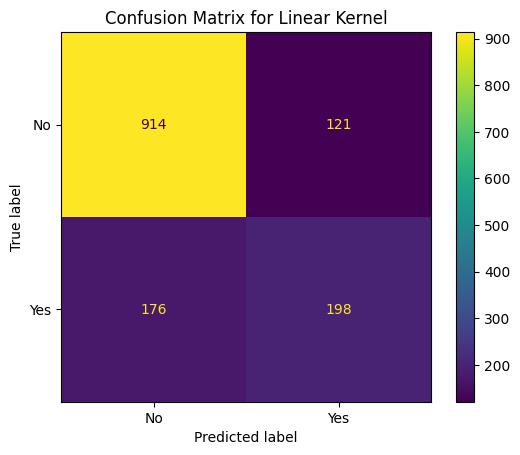

In [7]:
# YOUR CODE HERE — confusion matrix for the best kernel
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt

confusion = confusion_matrix(y_test, y_linear_pred)
ConfusionMatrixDisplay(confusion, display_labels=['No', 'Yes']).plot()
plt.title('Confusion Matrix for Linear Kernel')
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*The Linear kernel produced the highest F1-score of 0.5714, followed by RBF at 0.5562 and Polynomial at 0.5395. This is slightly surprising because RBF and Polynomial kernels can learn nonlinear decision boundaries, which may capture more complex relationships in customer churn data. However, the Linear kernel performed best on this test set.*

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*The Polynomial kernel used the most support vectors, with 2,738, followed by RBF with 2,660 and Linear with 2,569. A high support-vector count suggests that the model relies on many training points to define its decision boundary, which may indicate a more complex boundary or overlapping classes.*

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*I would carry forward the Linear kernel because it achieved the highest test F1-score of 0.5714, compared with 0.5562 for RBF and 0.5395 for Polynomial. It also used the fewest support vectors (2,569), suggesting a relatively simpler decision boundary. Therefore, the Linear kernel is the strongest choice based on the observed test performance and support-vector count.*


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

x_train_pca = pca.fit_transform(x_train_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:", explained_variance)
print("Total Explained Variance:", explained_variance.sum())


Explained Variance Ratio: [0.33244768 0.11982102]
Total Explained Variance: 0.45226870294223326


In [9]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
from sklearn.svm import SVC

C_values = [0.01, 1, 100]

models = {}

for c in C_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(x_train_pca, y_train)
    models[c] = model
    print("C = ", c)
    print("Support Vectors:", model.support_.shape[0])

C =  0.01
Support Vectors: 2997
C =  1
Support Vectors: 2658
C =  100
Support Vectors: 2635


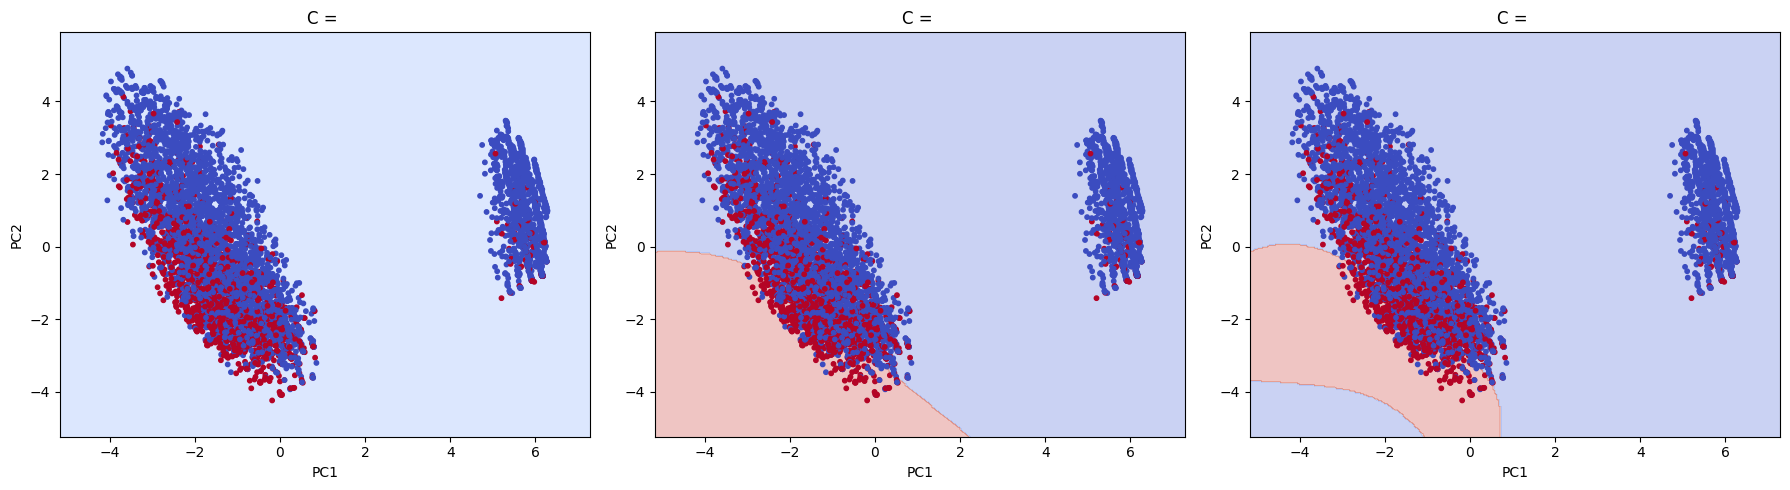

In [14]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
import numpy as np
import matplotlib.pyplot as plt

x_min = x_train_pca[:, 0].min() - 1
x_max = x_train_pca[:, 0].max() + 1
y_min = x_train_pca[:, 1].min() - 1
y_max = x_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

plt.figure(figsize=(18, 5))

for i, c in enumerate([0.01, 1, 100]):

    model = models[c]

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.subplot(1, 3, i + 1)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    plt.scatter(
        x_train_pca[:, 0],
        x_train_pca[:, 1],
        c=y_train,
        cmap='coolwarm',
        s=10
    )

    plt.title("C = ")
    plt.xlabel("PC1")
    plt.ylabel("PC2")

plt.tight_layout()
plt.show()


**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:As C increases, the decision boundary becomes more focused on correctly classifying training points. With a small C (0.01), the boundary is smoother and allows more classification errors. With a large C (100), the boundary becomes more sensitive to individual data points and may become more complex.*

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:As C increases, the number of support vectors generally decreases because the model tries harder to classify training points correctly. This matches the general SVM theory, although the actual number depends on the dataset.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:C = 0.01 looks like underfitting because it produces a simpler boundary and allows more classification errors. C = 100 may show overfitting because its boundary is more sensitive to individual training points. C = 1 provides a more balanced decision boundary.*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:The original dataset contains 30 features, but PCA reduces them to only 2 dimensions. This means some information is lost during dimensionality reduction. The 2-D plot cannot show all the relationships present in the original dataset. Therefore, the displayed decision boundary may look different from the actual high-dimensional SVM boundary, and it may give a misleading impression of the model's real performance.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [16]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.01, 0.1, 1]
}

from sklearn.model_selection import GridSearchCV

gs = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')
gs.fit(x_train_scaled, y_train)
print(gs.best_params_)
print(gs.best_score_)


{'C': 10, 'gamma': 0.01}
0.5852822456612709


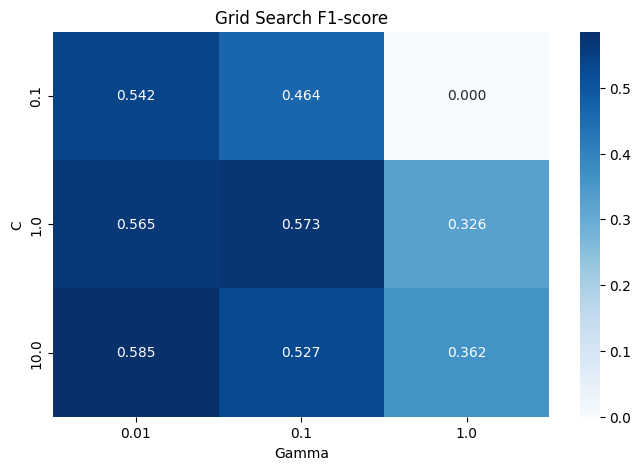

In [17]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results = pd.DataFrame(gs.cv_results_)

heatmap_data = results.pivot(index='param_C',columns='param_gamma',values='mean_test_score')

plt.figure(figsize=(8, 5))

sns.heatmap(heatmap_data,annot=True,cmap='Blues',fmt='.3f')

plt.title('Grid Search F1-score')
plt.xlabel('Gamma')
plt.ylabel('C')

plt.show()


In [18]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

best_estimator = gs.best_estimator_

y_pred = best_estimator.predict(x_test_scaled)
print("Best Parameters:", gs.best_params_)
print("Best CV Score:", gs.best_score_)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))


Best Parameters: {'C': 10, 'gamma': 0.01}
Best CV Score: 0.5852822456612709
Accuracy: 0.7885024840312278
Precision: 0.62751677852349
Recall: 0.5
F1-score: 0.5565476190476191


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:The best parameters found by GridSearchCV were C = 10 and gamma = 0.01. The corresponding cross-validated F1-score was 0.5853. These values provided the best performance among the tested parameter combinations.*

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:The best parameters found by GridSearchCV were C = 10 and gamma = 0.01. The corresponding cross-validated F1-score was 0.5853. These values provided the best performance among the tested parameter combinations.*

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:The cross-validated F1-score was 0.5853, while the final test F1-score was 0.5565. There is a small gap of approximately 0.0287. This suggests that the model generalizes reasonably well to unseen data. A large gap would suggest possible overfitting or poor generalization.*

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:The untuned RBF model achieved a test F1-score of 0.5562, while the tuned RBF model achieved 0.5565. The improvement was very small (approximately 0.0003). Therefore, hyperparameter tuning provided almost no improvement in test performance, suggesting that the default RBF model was already performing similarly.*


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [19]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Normal RBF model
svm_normal = SVC(kernel='rbf', C=10, gamma=0.01)
svm_normal.fit(x_train_scaled, y_train)
y_normal = svm_normal.predict(x_test_scaled)

# Balanced RBF model
svm_balanced = SVC(kernel='rbf', C=10, gamma=0.01,class_weight='balanced')

svm_balanced.fit(x_train_scaled, y_train)
y_balanced = svm_balanced.predict(x_test_scaled)

print("Normal Model")
print("Precision:", precision_score(y_test, y_normal))
print("Recall:", recall_score(y_test, y_normal))
print("F1-score:", f1_score(y_test, y_normal))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_normal))

print("\nBalanced Model")
print("Precision:", precision_score(y_test, y_balanced))
print("Recall:", recall_score(y_test, y_balanced))
print("F1-score:", f1_score(y_test, y_balanced))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_balanced))


Normal Model
Precision: 0.62751677852349
Recall: 0.5
F1-score: 0.5565476190476191
Confusion Matrix:
[[924 111]
 [187 187]]

Balanced Model
Precision: 0.5069686411149826
Recall: 0.7780748663101604
F1-score: 0.6139240506329114
Confusion Matrix:
[[752 283]
 [ 83 291]]


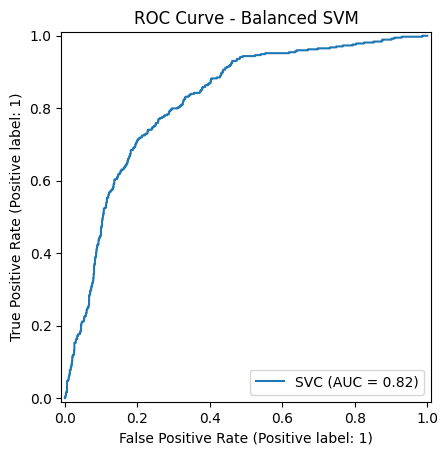

In [20]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(svm_balanced, x_test_scaled, y_test)

plt.title("ROC Curve - Balanced SVM")
plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:After switching to class_weight='balanced', precision decreased from 0.6275 to 0.5070, while recall increased from 0.5000 to 0.7781. This means the balanced model identifies more actual churn customers but also produces more false positives. The balanced model improves recall significantly.*

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:Missing an actual churn customer (False Negative) is more costly because the business loses an opportunity to retain that customer. Therefore, I would deploy the Balanced SVM because its recall is 0.7781 compared to 0.5000 for the normal model. Although its precision is lower, it identifies more customers who are likely to leave, helping the business take retention actions.*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:SVM does not directly provide probability estimates by default. To obtain probability-like scores, we enable probability=True in the SVC constructor. After training, we use the predict_proba() method to obtain estimated probabilities for each class.*


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [22]:
# YOUR CODE HERE — cross-model comparison table
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

dt = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(random_state=42)
lr = LogisticRegression(max_iter=1000, random_state=42)
knn = KNeighborsClassifier(n_neighbors=5)
svm = SVC(kernel='rbf', C=10, gamma=0.01,class_weight='balanced', random_state=42)

dt.fit(x_train, y_train)
rf.fit(x_train, y_train)
lr.fit(x_train_scaled, y_train)
knn.fit(x_train_scaled, y_train)
svm.fit(x_train_scaled, y_train)

dt_pred = dt.predict(x_test)
rf_pred = rf.predict(x_test)
lr_pred = lr.predict(x_test_scaled)
knn_pred = knn.predict(x_test_scaled)
svm_pred = svm.predict(x_test_scaled)

model_names = ['Decision Tree', 'Random Forest', 'Logistic Regression', 'KNN', 'SVM']

predictions = [dt_pred, rf_pred, lr_pred, knn_pred, svm_pred]

results = []

for name, pred in zip(model_names, predictions):
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred)
    })

comparison_df = pd.DataFrame(results)

comparison_df


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.741661,0.513889,0.494652,0.504087
1,Random Forest,0.787793,0.627986,0.491979,0.551724
2,Logistic Regression,0.806955,0.658385,0.566845,0.609195
3,KNN,0.747339,0.525281,0.500000,0.512329
4,SVM,0.740241,0.506969,0.778075,0.613924


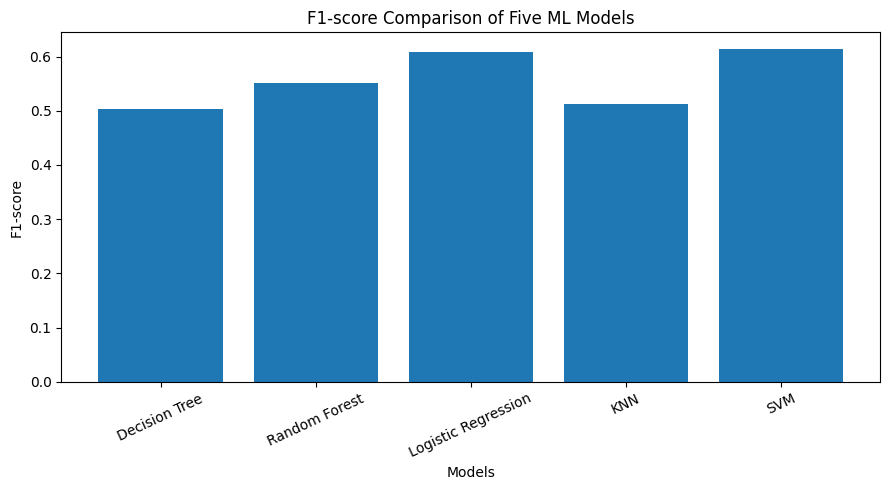

In [23]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(comparison_df['Model'], comparison_df['F1-score'])

plt.xlabel('Models')
plt.ylabel('F1-score')
plt.title('F1-score Comparison of Five ML Models')

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()



**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:SVM achieved the highest F1-score of 0.6139, followed by Logistic Regression at 0.6092. SVM also achieved the highest recall of 0.7781. Therefore, both F1-score and recall are highest for the same model, SVM.*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:Yes, the extra training cost was worth it because SVM achieved the highest F1-score (0.6139) and recall (0.7781) among all five models. Although SVM takes longer to train, it identifies more customers who are likely to churn, which is important for customer retention.*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:I would recommend deploying the SVM model because it achieved the highest F1-score of 0.6139 and the highest recall of 0.7781. Although Logistic Regression achieved slightly higher accuracy (0.8070) and precision (0.6584), SVM identifies more actual churn customers. Since missing potential churn customers can cause business losses, SVM is a better choice for this business problem.*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [24]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd
final_model = svm_balanced

y_pred = final_model.predict(x_test_scaled)

y_score = final_model.decision_function(x_test_scaled)

predictions_df = pd.DataFrame({
    'True_Label': y_test.values,
    'Predicted_Label': y_pred,
    'Predicted_Churn_Score': y_score
})

predictions_df.to_csv('svm_predictions.csv', index=False)

predictions_df.head()

,True_Label,Predicted_Label,Predicted_Churn_Score
0,0,0,-1.369712
1,0,1,1.403268
2,0,0,-1.511111
3,0,1,0.573009
4,0,0,-1.577039


**Executive Summary**

*### Executive Summary

In this lab, I compared five machine learning algorithms to predict customer churn using the Telco Customer Churn dataset. These algorithms included Decision Tree, Random Forest, Logistic Regression, KNN, and SVM. I selected the Balanced RBF SVM with C=10 and gamma=0.01 because it achieved the highest F1-score of 0.6139 and recall of 0.7781. Its accuracy was 0.7402 and precision was 0.5070. Using balanced class weights reduced false negatives from 187 to 83, helping identify more customers who might leave. However, this also increased false positives, meaning more loyal customers were incorrectly identified as potential churners. One limitation of this analysis is that the model was evaluated on a single train-test split, so its performance may vary on new customer data.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:The most surprising result was that using class_weight='balanced' significantly increased the SVM recall from 0.5000 to 0.7781. It also improved the F1-score from 0.5565 to 0.6139. This showed how handling class imbalance can improve a model's ability to identify customers who are likely to leave.*

(b) If you had one more hour, what would you try next?

*Your answer:If I had one more hour, I would try more hyperparameter combinations using GridSearchCV and experiment with different decision thresholds. I would also compare the results using cross-validation to check whether the model performs consistently. This could help improve recall while maintaining acceptable precision.*
